# Atom interferometer with internal clocks in gravity

A number $N$ of bosonic two-level atoms, with internal states *ground* ($g$) and *excited* ($e$), enter a Mach–Zehnder interferometer:

1. All the atoms enter the same port, in the ground state;
2. The first beam splitter (BS) puts them in a superposition of the two arms;
3. Within each arm, the atoms are held at a fixed height by Bloch oscillations;
4. The second BS recombines the arms.

**Summary:**

| Section  | What it does |
|------|---|
| 1. Setup | imports `spinlib` (built by `notebook_cpy_playground.ipynb`) |
| 2. First beam splitter  | applying first BS and computing the path qudit coefficients $B_{N^d}$ |
| 3. Ramsey sequence within each arm  | evolving and computing the internal qudit coefficients $C^{N^I}_{N^I_g}$ |
| 4. Second beam splitter  | reordering by the number of ground atoms $N_g$ and applying second BS |
| 5. Scan in time of Zych and Paczos | exact results, the whole sequence as a function of $T$, Zych (2011) and Paczos (2025) |


**Conventions.** A qudit of dimension $n+1$ is a spin $n/2$; index $k = 0,\dots,n$ is $|n/2, n/2 - k\rangle$.\
In this notebook $k = J - m$ always **counts atoms**: 
- In Sec. 2, $k = N^d$ for the path qudit (atoms in the down arm);
- In Sec. 3, $k = N^I_g$ for an internal qudit (atoms in the ground $g$);

where $I$ denotes the *down* ($d$) and *up* ($u$) paths of the interferometer. 
The notation $|\cdot\rangle\!\rangle$ denotes the *path* (external) state of all the atoms, while $|\cdot\rangle_d$ and $|\cdot\rangle_u$ denote the *internal* collective state of the atoms in arm $d$ and $u$. 

## 1. Setup

This notebook only **imports** the Python module `spinlib`, built by section 1 of `notebook_cpy_playground.ipynb` from the C++ sources in `./src_cpp`. Run that section once before this notebook, and again after any change to `qudit.hpp` or `spin_bindings.cpp`.

In [215]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

# Folder where notebook_cpy_playground.ipynb built spinlib (relative to this notebook, or an absolute path).
SRC = os.path.abspath("./src_cpp")

sys.path.insert(0, SRC)                      # Python looks for modules in the folders of sys.path: add SRC
import spinlib                               # ModuleNotFoundError: run section 1 of the playground notebook first

Here we also set the simulation parameters, in SI units (time in s, frequencies in rad/s):

In [216]:
# ----- Simulation -----
N = 50                          # total number of atoms
Tbloch = 1.                     # s, time between the two clock pulses
timeSteps = 500                 # number of time steps for the simulation
chi = 0.0                       # rad/s, optional one-axis twisting

# ----- Physical constants (SI) -----
hbar = 1.054571817e-34          # J s
c = 299792458.0                 # m/s
amu = 1.66053906660e-27         # kg, atomic mass unit
g = 9.81                        # m/s^2

The physical values are orders of magnitude for a trapped-atom interferometer with strontium: arms $\Delta z \sim 10\ \mu m$ apart, held for $T_B \sim 1\ s$, Bloch velocity $v_B \sim 10\ mm/s$.
Each arm $I = d, u$ enters the simulation through three numbers:
* `omegaE`: the internal (clock) frequency $\omega_I = \Delta E_I / \hbar$ in that arm, i.e. the energy of $e$ above $g$. The original frequency $\omega_0$ is redshifted by the height, $(1 + g z_I/c^2)$, and by the motion in the lattice, $(1 - \varepsilon_k)$ with $\varepsilon_k = \langle v^2\rangle/2c^2$.The two clock pulses come from a laser of frequency $\omega_{\rm L}$, so in its frame: 
$$\omega_I = \omega_0(1 - \varepsilon_k + g z_I/c^2) - \omega_{\rm L}\,.$$
* `omegaV`: the external frequency $\Omega_I = V_I/\hbar$ per atom, with $V_I = m g z_I$ for an atom held at height $z_I$;
* `varphi`: a constant external phase $\varphi_I$ per atom (e.g. from the free-fall parts of a real interferometer).

In [217]:
# ----- Atom: 87Sr, optical clock transition 1S0 - 3P0 -----
mass = 87 * amu                    # kg
omega0 = 2 * np.pi * 429.228e12    # rad/s, transition frequency (429 THz)

# ----- Clock laser -----
detuning = 2 * np.pi * 0.25        # rad/s, omega0 - omega_L: a quarter turn of the Ramsey phase in 1 s

# ----- Trapped interferometer -----
heights = {"d": 0.0, "u": 10e-6}   # m, heights of the two lattices: separation 10 um
vB = 10e-3                         # m/s, Bloch velocity: <v^2> = vB^2 / 3 within one oscillation

# ----- Relativistic corrections -----
eps_k = vB**2 / 3 / (2 * c**2)     # motional time dilation <v^2> / 2c^2, the same in both arms
redshift = {arm: g * heights[arm] / c**2 for arm in ("d", "u")} # gravitational redshift g z / c^2

# ----- Per-arm parameters (rad/s, in the frame of the clock laser) 
# The clock frequency omega0 (1 - eps_k + g z/c^2) - omega_L  =  detuning + omega0 (g z/c^2 - eps_k)
omegaE = {arm: detuning + omega0 * (redshift[arm] - eps_k) for arm in ("d", "u")}
# The external frequency m g z / hbar
omegaV = {arm: mass * g * heights[arm] / hbar for arm in ("d", "u")}
# The external phase
varphi = {arm: 0. for arm in ("d", "u")}

The printout gives the scales of the effects: with these values the gravitational phase $m g \Delta z\,T/\hbar$ is
huge, while the visibility loss due to the redshift is of order ~$10^{-12}$.
Full loss of visibility needs $\Delta z\,T_B = \pi c^2/(\omega_0 g) \approx 10$ m s.

In [218]:
dw = omega0 * g * (heights["u"] - heights["d"]) / c**2 # = omegaE["u"] - omegaE["d"]  ----- gravitational redshift
dV = mass * g * (heights["u"] - heights["d"]) / hbar   # = omegaV["u"] - omegaV["d"]  ---  gravitational frequency
omega_bar = (omegaE["u"] + omegaE["d"]) / 2            # mean clock frequency in the laser frame (Ramsey frequency)

print(f"Redshift between the arms:   domega = (omega0 g dz)/c^2 = {dw:.3e} rad/s   (fractional {dw / omega0:.1e})")
print(f"Gravitational phase shift:   (m g dz)/hbar = {dV:.3e} rad/s,  i.e. {dV * Tbloch:.3e} rad in Tbloch")
print(f"Motional clock shift:        omega0 eps_k = {omega0 * eps_k:.3e} rad/s, the same in both arms")
print(f"Visibility after Tbloch:     cos(domega T/2) = 1 - {1 - np.cos(dw * Tbloch / 2):.3e}\n")

# Time scales: the period of each fringe, and the time at which the visibility first vanishes.
print(f"Period Ramsey fringe of P(N_g)       :   2 pi/omega_bar = {2 * np.pi / abs(omega_bar):.3f} s")
print(f"Period Gravitational fringe of P(N^d):   2 pi/(m g dz/hbar) = {2 * np.pi / abs(dV) * 1e6:.3f} us")
print(f"Full loss of visibility for   Tbloch =   pi/domega0 = {np.pi / abs(dw):.3e} s  ({np.pi / abs(dw) / 86400:.3f} days) ")

Redshift between the arms:   domega = (omega0 g dz)/c^2 = 2.944e-06 rad/s   (fractional 1.1e-21)
Gravitational phase shift:   (m g dz)/hbar = 1.344e+05 rad/s,  i.e. 1.344e+05 rad in Tbloch
Motional clock shift:        omega0 eps_k = 5.001e-07 rad/s, the same in both arms
Visibility after Tbloch:     cos(domega T/2) = 1 - 1.083e-12

Period Ramsey fringe of P(N_g)       :   2 pi/omega_bar = 4.000 s
Period Gravitational fringe of P(N^d):   2 pi/(m g dz/hbar) = 46.754 us
Full loss of visibility for   Tbloch =   pi/domega0 = 1.067e+06 s  (12.352 days) 


For later convenience, let us introduce a function to update the parameters and return the above ones when called with no arguments:


In [219]:
def update_parameters(z_d=heights["d"], z_u=heights["u"], detuning=detuning, vB=vB,
                        varphi_d=0.0, varphi_u=0.0, mass=mass, omega_0=omega0):
    z = {"d": z_d, "u": z_u}
    eps_k = vB**2 / 3 / (2 * c**2)                       # motional time dilation <v^2>/2c^2
    # Clock frequency omega_0 (1 - eps_k + g z/c^2) - omega_L  =  detuning + omega_0 (g z/c^2 - eps_k)
    omegaE = {arm: detuning + omega_0 * (g * z[arm] / c**2 - eps_k) for arm in z}
    # External frequency m g z / hbar
    omegaV = {arm: mass * g * z[arm] / hbar for arm in z}
    # Constant external phase per atom
    varphi = {"d": varphi_d, "u": varphi_u}
    return omegaE, omegaV, varphi

# Usage example:
omegaE, omegaV, varphi = update_parameters()

**Note on numerical precision.** The code takes the detuning $\omega_0 - \omega_{\rm L}$ as the input and adds the tiny relativistic shifts $\omega_0(g z_I/c^2 - \varepsilon_k)$ separately. This is because $\omega_0$ has magnitude $10^{15}$ and cannot be stored with any useful number of digits after the decimal point. Hence, we cannot compute a small physical difference as the difference of two large numbers. The same problem might emerge in other computations for large $T$.

## 2. First beam splitter

**Path qudit.** The $N$ atoms are distributed between the two arms such that
$$ N = 2J = N^u + N^d, \qquad 2J^z = N^u - N^d, $$
from which
$$N^d = J - m, \qquad N^u = N - N^d .$$


A path state with $N^d$ atoms down, all of them in the ground $g$, reads as
$$ |N^d, N-N^d\rangle\!\rangle  \equiv |J = \tfrac{N}{2},\ m = J - N^d\rangle\!\rangle
  := |\tfrac{N^d}{2}, -\tfrac{N^d}{2}\rangle_d\,|\tfrac{N^u}{2}, -\tfrac{N^u}{2}\rangle_u .$$
For instance:
$$\begin{aligned}
|N^d = N,\ N^u = 0\rangle\!\rangle &= |\tfrac{N}{2}, -\tfrac{N}{2}\rangle\!\rangle = |\tfrac{N}{2}, -\tfrac{N}{2}\rangle_d\,|0, 0\rangle_u ,\\
|N^d = N-1,\ N^u = 1\rangle\!\rangle &= |\tfrac{N}{2}, -\tfrac{N}{2} + 1\rangle\!\rangle = |\tfrac{N-1}{2}, \tfrac{1-N}{2}\rangle_d\,|\tfrac{1}{2}, -\tfrac{1}{2}\rangle_u ,\\
&\ \,\vdots\\
|N^d = 0,\ N^u = N\rangle\!\rangle &= |\tfrac{N}{2}, \tfrac{N}{2}\rangle\!\rangle = |0, 0\rangle_d\,|\tfrac{N}{2}, -\tfrac{N}{2}\rangle_u .
\end{aligned}$$


The collective path spin starts with all atoms in the lower arm as

$$ \texttt{quditDU} = |\tfrac{N}{2},\ - \tfrac{N}{2}\rangle\!\rangle \,. $$

To initialize the path qudit, we write:

In [220]:
quditDU = spinlib.Qudit(N + 1, "CSS-Z")
print("The number of particles in the lower arm Nd is:", int(N/2 -  quditDU.avgSpin()[2]))
print("The number of particles in the upper arm Nu is:", int(N/2 +  quditDU.avgSpin()[2]))

The number of particles in the lower arm Nd is: 50
The number of particles in the upper arm Nu is: 0


**First BS.** All the atoms start in one port, i.e. the path qudit starts in $|J, -J\rangle\!\rangle$, and the
BS is a $\pi/2$ pulse along $y$:
$$ \texttt{quditDU} \longrightarrow  e^{-i\pi \hat J^y/2}\,|J, -J\rangle\!\rangle = \sum_{m=-J}^{+J} B_m\,|J, m\rangle\!\rangle = \sum_{N^d=0}^{N} B_{N^d}\,|\tfrac{N^d}{2}, -\tfrac{N^d}{2}\rangle_d\,|\tfrac{N - N^d}{2}, -\tfrac{N - N^d}{2}\rangle_u .$$
Since the library index is $k = N^d = J - m $, the coefficient $B_{N^d}$ is simply `quditDU.amplitude(k)`.

In [221]:
quditDU.applyPulseYPiHalf()            # path qudit after the first BS
stateQuditDU = np.asarray(quditDU.state())        # stateQuditDU[Nd] = B_{Nd}, amplitude with Nd atoms down
print(f"The amplitude corresponding to Nd = 0 is: {stateQuditDU[0]:.3f}")

The amplitude corresponding to Nd = 0 is: 0.000+0.000j


**Expected:** $|B_{N^d}|^2 = \binom{N}{N^d}/2^N$, each atom independently down or up with probability $1/2$.

Max | |B|^2 - binomial | = 0.000


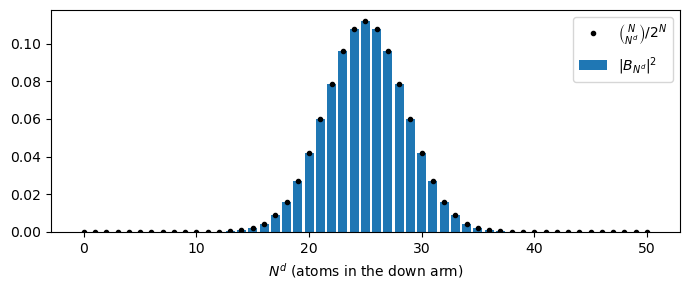

In [222]:
Nd = np.arange(N + 1)
# C(N, Nd) / 2^N: squared moduli of a CSS on the equator (theta = pi/2), computed by spinlib without overflow.
binomial = np.asarray(spinlib.Qudit.cssModuli(N + 1, np.pi / 2))**2
print(f"Max | |B|^2 - binomial | = {np.abs(np.abs(stateQuditDU)**2 - binomial).max():.3f}")

plt.figure(figsize=(7, 3))
plt.bar(Nd, np.abs(stateQuditDU)**2, label=r"$|B_{N^d}|^2$")
plt.plot(Nd, binomial, "k.", label=r"$\binom{N}{N^d}/2^N$")
plt.xlabel(r"$N^d$ (atoms in the down arm)"); plt.legend(); plt.tight_layout(); plt.show()

## 3. Ramsey sequence within each arm 

**Internal qudits.** For any $N^d$, the atoms in each arm $I = d, u$ form a collective internal spin with
$$2J^z_I = N^I_e - N^I_g\;\implies\; N^I_g = (N^I/2) - J^z_I\,.$$
We start with all the atoms in the ground:
$$\texttt{quditDw} = |\tfrac{N^d}{2}, -\tfrac{N^d}{2}\rangle_d, \qquad \texttt{quditUp} = |\tfrac{N^u}{2}, -\tfrac{N^u}{2}\rangle_u .$$

For instance:

In [223]:
Nd = N // 2 + (3 if N > 8 else 0)

quditDw = spinlib.Qudit(Nd + 1, "CSS-Z")
quditUp = spinlib.Qudit(N - Nd + 1, "CSS-Z")

print("The number of particles in the ground state of the lower arm is:", int(Nd/2 -  quditDw.avgSpin()[2]))
print("The number of particles in the excited state of the lower arm is:", int(Nd/2 +  quditDw.avgSpin()[2]))
print("The number of particles in the ground state of the upper arm is:", int((N - Nd)/2 -  quditUp.avgSpin()[2]))
print("The number of particles in the excited state of the upper arm is:", int((N - Nd)/2 +  quditUp.avgSpin()[2]))

The number of particles in the ground state of the lower arm is: 28
The number of particles in the excited state of the lower arm is: 0
The number of particles in the ground state of the upper arm is: 22
The number of particles in the excited state of the upper arm is: 0


**Bloch oscillations.** Within each arm, the atoms are held at a fixed height while their internal state evolves.
The evolution is diagonal in the internal basis, so it only multiplies each amplitude by a phase. For $N^I$ atoms in arm
$I$, $N^I_e = N^I - N^I_g$ of them excited:

$$ \Phi_I(N^I, N^I_e) = N^I_e\,\omega_I \,T + N^I\Omega_I\,T + N^I \varphi_I\,.$$

* The term $\omega_I = \Delta E_I/ \hbar$ is the frequency difference between $g$ and $e$ within the same arm.
* The term $\Omega_I = m g z_I/\hbar$ is due to an external arm-dependent potential, the same for $g$ and $e$.
* The term $\varphi_I$ is a constant phase acquired by each atom in the same arm.

The frequencies for $n = N^I$ atoms in arm $d$ or $u$, labeled by the internal index $k = N^I_g$, are given by:

In [224]:
def frequencies(arm, n):
    k = np.arange(n + 1)
    return (n - k) * omegaE[arm] + n * omegaV[arm]

**Ramsey sequence**. Apply $\pi/2$ pulse along $y$, diagonal evolution, and $\pi/2$ pulse along $y$:
$$\begin{aligned}
\texttt{quditDw} &\longrightarrow \sum_{m=-N^d/2}^{N^d/2} C^{N^d}_m\,|\tfrac{N^d}{2}, m\rangle_d
  = \sum_{N^d_g=0}^{N^d} C^{N^d}_{N^d_g}\,|\tfrac{N^d}{2}, \tfrac{N^d}{2} - N^d_g\rangle_d ,\\
\texttt{quditUp} &\longrightarrow \sum_{N^u_g=0}^{N-N^d} C^{N^u}_{N^u_g}\,|\tfrac{N-N^d}{2}, \tfrac{N-N^d}{2} - N^u_g\rangle_u .
\end{aligned}$$
Here too the library index counts atoms: $k = N^I_g = \tfrac{N^I}{2} - m $. Hence, the coefficient $C^{N^I}_{N^I_g}$ is entry $k$ of
`state()`.

In [225]:
def oscillations(arm, n, T):
    # n atoms, all in g ("CSS-Z")  ->  pi/2 along y  ->  free evolution  ->  pi/2 along y.
    q = spinlib.Qudit(n + 1, "CSS-Z")
    # Apply first Pi/2 pulse
    q.applyPulseYPiHalf()
    # evolveDiagonal(E, t) multiplies amplitude k by exp(-i E_k t).
    q.evolveDiagonal(frequencies(arm, n), T)
    # Constant external phase n*varphi, the same for every internal state.
    q.evolveDiagonal(np.full(n + 1, n * varphi[arm]), 1.0)
    # Apply last pulse and return the state
    q.applyPulseYPiHalf()
    return np.asarray(q.state())

**Execution and storage**. One row per $N^d = 0, \dots, N$, such that:
$$\begin{bmatrix}\;
\begin{aligned}
\texttt{quditDU.amplitude}(0),\ \ &\texttt{quditDw.state()},\ \ \texttt{quditUp.state()}\
\\  
\texttt{quditDU.amplitude}(1),\ \ &\texttt{quditDw.state()},\ \ \texttt{quditUp.state()}\  
\\
&\vdots
\\
 \texttt{quditDU.amplitude}(N),\ \ &\texttt{quditDw.state()},\ \ \texttt{quditUp.state()}\  
\end{aligned}\;\end{bmatrix}$$

In [226]:
coefficients = []                                        # row Nd: [B_Nd, C^{Nd}_{Ng}, C^{Nu}_{Ng}]
for Nd in range(N + 1):
    stateQuditDw = oscillations("d", Nd, Tbloch)              # internal state of the Nd atoms in the down arm
    stateQuditUp = oscillations("u", N - Nd, Tbloch)          # internal state of the Nu atoms in the up arm
    coefficients.append([stateQuditDU[Nd], stateQuditDw, stateQuditUp])

For instance:

In [227]:
Nd = N // 2 + (3 if N > 8 else 0)
print(f"Row Nd = {Nd}:  B_{Nd} = {coefficients[Nd][0]:.3f}", 
      "\n The state vector of quditDw C^{Nd}_{Ng} has ", len(coefficients[Nd][1]), "amplitudes."
      f"\n The amplitude corresponding to Nd = {Nd} and Nd_ground = 0  is: {coefficients[Nd][1][0]:.3f}",
      f"\n The amplitude corresponding to Nd = {Nd} and Nd_ground = Nd is: {coefficients[Nd][1][Nd]:.3f}",
      "\n The state vector of quditUp C^{Nu}_{Ng} has ", len(coefficients[Nd][2]), "amplitudes."
      f"\n The amplitude corresponding to Nu = {N - Nd} and Nu_ground = 0  is: {coefficients[Nd][2][0]:.3f}",
      f"\n The amplitude corresponding to Nu = {N - Nd} and Nu_ground = Nu is: {coefficients[Nd][2][N - Nd]:.3f}")

Row Nd = 28:  B_28 = 0.281+0.000j 
 The state vector of quditDw C^{Nd}_{Ng} has  29 amplitudes.
 The amplitude corresponding to Nd = 28 and Nd_ground = 0  is: -0.000-0.000j 
 The amplitude corresponding to Nd = 28 and Nd_ground = Nd is: -0.000-0.000j 
 The state vector of quditUp C^{Nu}_{Ng} has  23 amplitudes.
 The amplitude corresponding to Nu = 22 and Nu_ground = 0  is: 0.000+0.000j 
 The amplitude corresponding to Nu = 22 and Nu_ground = Nu is: -0.000-0.000j


**Resulting state**.
Before the second beam splitter the state is
$$|\Psi\rangle\!\rangle = \sum_{N^d=0}^{N} B_{N^d}
   \sum_{N^d_g=0}^{N^d} C^{N^d}_{N^d_g}\,|\tfrac{N^d}{2}, \tfrac{N^d}{2} - N^d_g\rangle_d
   \sum_{N^u_g=0}^{N-N^d} C^{N^u}_{N^u_g}\,|\tfrac{N-N^d}{2}, \tfrac{N-N^d}{2} - N^u_g\rangle_u ,$$
whose coefficients are the rows stored above. 

The states with different $N^d$ are orthogonal and each internal
state is normalised, so **expected:** $\sum_{N^d}|B_{N^d}|^2\,\|C^{N^d}\|^2\,\|C^{N^u}\|^2 = 1$.

In [228]:
norm2 = sum(abs(b)**2 * np.sum(np.abs(Cd)**2) * np.sum(np.abs(Cu)**2) for b, Cd, Cu in coefficients)
print(f" The norm reads <<Psi|Psi>> = {norm2:.3f}")

 The norm reads <<Psi|Psi>> = 1.000


## 4. Second beam splitter

**Basis change.** The second BS mixes the arms without touching the internal state, so it conserves the number of ground atoms $N_g = N^d_g + N^u_g$ and of excited atoms $N_e = N - N_g$. Hence, the total state $|\Psi\rangle\!\rangle$ is regrouped into sectors of fixed $N_g$ as

$$|\Psi\rangle\!\rangle = \bigoplus_{N_g} \sum_{N^d_g=0}^{N_g} \sum_{N^d_e=0}^{N-N_g} |\tfrac{N_g}{2}, \tfrac{N_g}{2} - N^d_g\rangle\,|\tfrac{N - N_g}{2}, \tfrac{N - N_g}{2} - N^d_e\rangle\,\langle\,\cdots|\Psi\rangle\!\rangle\,,$$

where the ground atoms form a path qudit of $N_g$ bosons, and the excited atoms another one of $N_e = N - N_g$ bosons. 

**Amplitudes.** Within each sector $N_g$, this state can be equivalently represented as a matrix of coefficients:

$$ \Psi_{N_g}(N^d_g, N^d_e) := \left( \langle\tfrac{N_g}{2}, \tfrac{N_g}{2} - N^d_g|\langle\tfrac{N - N_g}{2}, \tfrac{N - N_g}{2} - N^d_e|\right) \,|\Psi\rangle\!\rangle \,,$$


having size $(N_g + 1)\times(N - N_g + 1)$. For fixed $N_g$, the amplitude with $N^d_g$ ground and $N^d_e$ excited atoms in the down arm is

$$\Psi_{N_g}(N^d_g, N^d_e) = B_{N^d}\; C^{N^d}_{N^d_g}\; C^{N^u}_{N^u_g}\,,$$

where $N^d$, $N^u$, and $N^u_g$ are automatically determined by $N_g$, $N^d_g$, and $N^d_e$ as

$$ N^d = N^d_g + N^d_e,\quad N^u = N - N^d,\quad N^u_g = N_g - N^d_g \,.$$

This amplitude is stored in coefficients as `coefficients[Nd][0] * coefficients[Nd][1][Ndg] * coefficients[Nd][2][Nug]`.

In [229]:
# Original code: 20 times slower
#coeffSector = {}
#for Ng in range(N + 1):
#    M = np.zeros((Ng + 1, N - Ng + 1), dtype=complex)
#    for ndg in range(Ng + 1):                        # N^d_g
#        for nde in range(N - Ng + 1):                # N^d_e
#            B, Cd, Cu = coefficients[ndg + nde]      # row N^d = N^d_g + N^d_e
#            M[ndg, nde] = B * Cd[ndg] * Cu[Ng - ndg] # C^{N^d}_{N^d_g} C^{N^u}_{N^u_g}
#    coeffSector[Ng] = M

# Put the coefficients in two zero-padded tables, so that NumPy can index them all at once:
#     Cd[Nd, Ndg] = C^{Nd}_{Ndg},   Cu[Nu, Nug] = C^{Nu}_{Nug}.
Bs = np.array([row[0] for row in coefficients])          # Bs[Nd] = B_{Nd}
Cd = np.zeros((N + 1, N + 1), dtype=complex)
Cu = np.zeros((N + 1, N + 1), dtype=complex)
for Nd, (_, cd, cu) in enumerate(coefficients):
    Cd[Nd, :Nd + 1] = cd
    Cu[N - Nd, :N - Nd + 1] = cu

coeffSector = {}
for Ng in range(N + 1):
    ndg = np.arange(Ng + 1)[:, None]                     # N^d_g, one per row    (column vector)
    nde = np.arange(N - Ng + 1)[None, :]                 # N^d_e, one per column (row vector)
    Nd = ndg + nde                                       # N^d = N^d_g + N^d_e for every entry (broadcasting)
    # B_{N^d} C^{N^d}_{N^d_g} C^{N^u}_{N^u_g},  with N^u = N - N^d and N^u_g = N_g - N^d_g
    coeffSector[Ng] = Bs[Nd] * Cd[Nd, ndg] * Cu[N - Nd, Ng - ndg]

The reordered data structure is a matrix `coeffSector[Ng]` for every $N_g$. The rows span different $N^d_g$ of the ground path qudit, while the columns span the index $N^d_e$ of the excited one. This form is convenient for the second beam splitter, which acts on the two indices separately.

In [230]:
# Set N_ground
Ng = N // 2 + (3 if N > 8 else 0)
# Set Nd_ground 
Ndg = Ng // 2 + (3 if Ng > 8 else 0) 
# Set Nd_excited
Nde = (N - Ng) // 2 + (3 if (N - Ng) > 8 else 0)

# Check that they are physical
assert Ndg <= Ng 
assert Nde <= N - Ng

Nd = Nde + Ndg
Nug = Ng - Ndg
print(f"For Ng = {Ng}, Ndg = {Ndg}, Nde = {Nde}, we have    : {coefficients[Nd][0] * coefficients[Nd][1][Ndg] * coefficients[Nd][2][Nug]:.3f}.")
print(f"The reordered table Psi_Ng (Ndg, Nde) gives : {coeffSector[Ng][Ndg, Nde]:.3f}")

For Ng = 28, Ndg = 17, Nde = 14, we have    : 0.009-0.020j.
The reordered table Psi_Ng (Ndg, Nde) gives : 0.009-0.020j


**Sector states.** The total state is the sum of these orthogonal pieces, $|\Psi\rangle\!\rangle = \sum_{N_g}|\Psi_{N_g}\rangle\!\rangle$, which is the $\bigoplus$ above. The amplitudes of one sector define the (unnormalised) sector state
$$|\Psi_{N_g}\rangle\!\rangle := \sum_{N^d_g=0}^{N_g}\sum_{N^d_e=0}^{N-N_g} \Psi_{N_g}(N^d_g, N^d_e)\,|\tfrac{N_g}{2}, \tfrac{N_g}{2} - N^d_g\rangle\,|\tfrac{N - N_g}{2}, \tfrac{N - N_g}{2} - N^d_e\rangle \,,$$
i.e. the projection $\Pi_{N_g}|\Psi\rangle\!\rangle$ of the total state onto the sector.
By the Born rule, $P(N_g) = \langle\!\langle\Psi|\Pi_{N_g}|\Psi\rangle\!\rangle = \||\Psi_{N_g}\rangle\!\rangle\|^2$. A unitary that does not mix different sectors is block diagonal, $U = \bigoplus_{N_g} U_{N_g}$, so it leaves this probability unchanged:
$$P(N_g) = \big\|U_{N_g}|\Psi_{N_g}\rangle\!\rangle\big\|^2 = \big\||\Psi_{N_g}\rangle\!\rangle\big\|^2 = \sum_{N^d_g=0}^{N_g}\sum_{N^d_e=0}^{N-N_g}|\Psi_{N_g}(N^d_g, N^d_e)|^2 \,.$$
Each matrix element is the amplitude of one state of an orthonormal basis, so the squared norm is the sum of the squared moduli of all the elements of the matrix `coeffSector[Ng]`.

In [231]:
P_g = np.array([np.sum(np.abs(coeffSector[Ng])**2) for Ng in range(N + 1)])
print(f"The norm of the current state, i.e. the sum of the probabilities P(Ng), is : {np.sum(P_g):.3f}")

The norm of the current state, i.e. the sum of the probabilities P(Ng), is : 1.000


**Second BS.** The second beam splitter mixes the two arms without touching the internal states, so it acts in the same way on the ground and on the excited atoms. This is a $\pi/2$ pulse along $y$ on each path qudit, expressed as

$$D_{N_g}\otimes D_{N-N_g} \;\text{with} \; D_n = e^{-i\frac{\pi}{2}\hat J^y} \;\text{for spin } n/2 \,.$$

When a two-qudit state is written as a matrix of coefficients, $|\Phi\rangle = \sum_{k_g, k_e}\Phi(k_g, k_e)\,|k_g\rangle|k_e\rangle$, the action of an operator $U\otimes V$ reads as

$$(U\otimes V)\,|k_g\rangle|k_e\rangle = \sum_{a,b} U_{a k_g} V_{b k_e}\,|a\rangle|b\rangle\,.$$

The coefficient of $|a\rangle|b\rangle$ is then $\sum_{k_g,k_e} U_{a k_g}\,\Phi(k_g,k_e)\,V_{b k_e} = (U\Phi V^T)_{ab}$.
Hence, in each sector we have

$$(D_{N_g}\otimes D_{N-N_g})\,|\Psi_{N_g}\rangle\!\rangle = \sum_{k_g, k_e}\,\Psi'_{N_g}(k_g, k_e)\,|k_g\rangle|k_e\rangle \,, \quad \text{where}\;\Psi'_{N_g} = D_{N_g}\,\Psi_{N_g}\, D_{N-N_g}^{T}$$

i.e. two small matrix products instead of one operator on the whole Fock space.

In [232]:
for Ng in range(N + 1): coeffSector[Ng] = spinlib.Qudit.wignerDy(Ng + 1) @ coeffSector[Ng] @ spinlib.Qudit.wignerDy(N - Ng + 1).T

**Output statistics.** The second BS affects the probability $P(N^{I})$ that the atoms will end up in the up $I=u$ or down $I=d$ ports, whatever their internal state. In particular, they will all end up in the up port if the two arms acquire the same phase.

The interference between the arms shows up, for example, in a gravitational field. To compute the probability that $N^d = N^d_g + N^d_e$ atoms will leave from the down port, we must select and sum the squared amplitudes corresponding to $N^d$ among all sectors. 

In [233]:
P_d = np.zeros(N + 1)
for Ng, M in coeffSector.items():
    # Build a matrix the same shape as M with a[i, j] = i + j
    a = np.add.outer(np.arange(M.shape[0]), np.arange(M.shape[1]))
    # Filtered sum P_d[a[i, j]] += |M[i, j]|**2
    np.add.at(P_d, a, np.abs(M)**2)
print(f" The sum of any P(N^d) is : {P_d.sum():.3f}")

 The sum of any P(N^d) is : 1.000


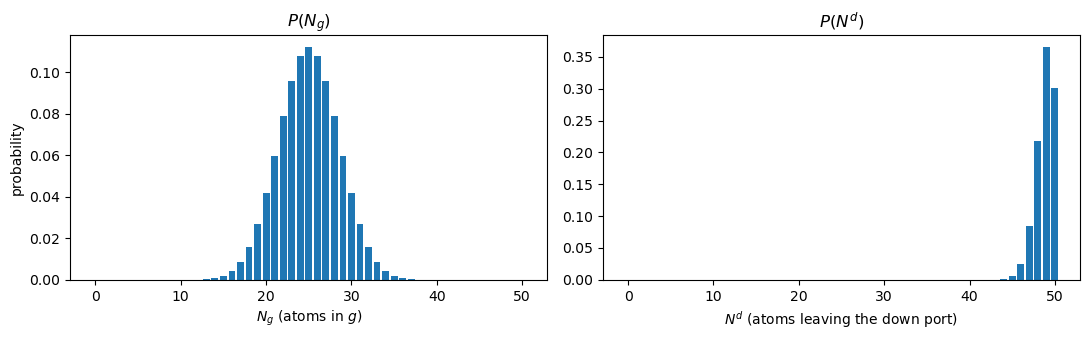

In [234]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(N + 1), P_g);   ax[0].set(xlabel=r"$N_g$ (atoms in $g$)", ylabel="probability", title=r"$P(N_g)$")
ax[1].bar(range(N + 1), P_d); ax[1].set(xlabel=r"$N^d$ (atoms leaving the down port)", title=r"$P(N^d)$")
plt.tight_layout(); plt.show()

Running again the last three cells, i.e. applying an additional BS, the plot on the right changes while the one on the left stays the same.

## 5. Scan in time, Zych and Paczos models

We first derive the exact single-atom results, then define compact functions that run the whole sequence for any $T$, and use them to reproduce two results from the literature.
Without squeezing the atoms evolve independently, so the exact results are binomial laws built from two single-atom probabilities: $p_g$, set by the Ramsey sequence in each arm, and $p_{\rm down}$, set by the interference of the arms at the second BS. 

The function `final_state(N, T)` repeats Secs. 2–4 for any time $T$, and `stats` and `means` extract the distributions $P(N_g)$, $P(N^d)$ and their means, which are checked against the exact laws. The same functions then reproduce the same results of Zych et al. (2011) and Paczos, Foo & Zych (2025).

### Exact results without squeezing 

The Hamiltonian is linear in the collective spins, so the atoms evolve independently: each atom is in the ground state $g$ with probability $p_g$ and leaves by the down port with probability $p_{\rm down}$, and both distributions are binomial as

$$P(N_g) = \binom{N}{N_g}\, p_g^{\,N_g}(1- p_g)^{N-N_g}, \qquad P(N^d) = \binom{N}{N^d}\,p_{\rm down}^{\,N^d}(1-p_{\rm down})^{N-N^d} .$$

Denoting by $a^I_s$ the amplitude of the internal state $s = g, e$ of one atom after the Ramsey sequence in arm $I$, we have

$$
a^I_g = \frac{1 - e^{-i\omega_I T}}{2} = i\,e^{-i\omega_I T/2}\,s_I, \qquad
a^I_e = -\frac{1 + e^{-i\omega_I T}}{2} = -e^{-i\omega_I T/2}\,c_I,
$$

where $s_I = \sin(\omega_I T/2)$ and $c_I = \cos(\omega_I T/2)$, and we omitted the external phase $e^{-i\theta_I}$, with $\theta_I = \Omega_I T + \varphi_I$, common to both internal states.


*Before the second BS*, an atom is in arm $I$ with probability $1/2$, and the Ramsey sequence leaves it in $g$ with probability $|a^I_g|^2 = s_I^2 = (1 - \cos\omega_I T)/2$. The probability to be in arm $I$ and in $g$ is then $p^I_g = \tfrac12 s_I^2 = (1 - \cos\omega_I T)/4$. Summing for $I = d,u$ we obtain:

$$ p_g = p^u_g + p^d_g = \frac12\Big[1 - \mathcal{V}(T)\cos\big(\bar\omega\,T\big)\Big]\,, \qquad \mathcal{V}(T) = \cos\big(\Delta\omega\,T/2\big)\,.$$

Here, the frequency shift $\Delta \omega = \omega_u - \omega_d = \omega_0 g \Delta z /c^2$ arises from the effect of gravity on the atom's internal energy levels, i.e. the gravitational redshift, and the detuning frequency

$$\bar\omega = (\omega_u + \omega_d) /2 = \omega_0\Big(1 - \varepsilon_k + {g z_d}/{c^2}\Big) + \Delta\omega /2- \omega_{\rm L}\,,$$

accounts for the effects of the gravitational field at the mean height. At fixed $T$, scanning $\omega_{\rm L}$ gives the Ramsey fringe centred at the resonance; changing $\Delta z$ at fixed $z_d$ changes the visibility $\mathcal V$ and shifts this resonance by $\Delta\omega/2$.



*After the second BS*, each atom leaves by the down port in state $s$ with amplitude $(a')_s^d = \big(a^d_s - a^u_s\,e^{-i\Delta\theta}\big)/2$, where $\Delta$ denotes the difference between the up and down parameters. The corresponding probabilities are

$$p'^d_g = \frac14\Big[s_d^2 + s_u^2 - 2\,s_d s_u\cos\Delta\Phi\Big], \qquad p'^d_e = \frac14\Big[c_d^2 + c_u^2 - 2\,c_d c_u\cos\Delta\Phi\Big],$$

where the last terms are the interference between the arms. Summing them we obtain:

$$p_{\rm down} = p'^d_g + p'^d_e = \frac12\Big[1 - \mathcal{V}(T)\cos\Delta\Phi\Big], \qquad \Delta\Phi = \Delta\Omega\,T + \Delta\varphi + \frac{\Delta\omega\,T}{2}.$$

Here, the external frequency shift $\Delta\Omega = m g\,\Delta z/\hbar$, due to the gravitational potential energy of the rest mass, is much larger than the redshift $\Delta\omega$ of the internal energy: their ratio $\Delta\Omega/\Delta\omega = mc^2/\hbar\omega_0$ is the rest energy of the atom over the energy of the clock transition, independent of $\Delta z$. 

In [235]:
def exact_probabilities(T):
    # Exact single-atom probabilities p_g and p_down with the current omegaE, omegaV, varphi.
    del_omega = omegaE["u"] - omegaE["d"]
    bar_omega = (omegaE["u"] + omegaE["d"]) / 2
    dPhi = (omegaV["u"] - omegaV["d"]) * T + (varphi["u"] - varphi["d"]) + del_omega * T / 2
    visibility = np.cos(del_omega * T / 2)

    pg = 0.5 * (1 - visibility * np.cos(bar_omega * T))
    pdown = 0.5 * (1 - visibility * np.cos(dPhi))
    return pg, pdown 

def binomial_law(n, p):
    # Binomial distribution of n independent atoms with single-atom probability p: the squared moduli of a CSS
    # of dimension n + 1 at theta = 2 arcsin(sqrt(p)), since |<J,m|theta>|^2 = C(n, k) p^k (1 - p)^(n - k).
    theta = 2 * np.arcsin(np.sqrt(np.clip(p, 0.0, 1.0)))        # clip: rounding could give p = 1 + 1e-16
    return np.asarray(spinlib.Qudit.cssModuli(n + 1, theta))**2

# The exact probability distributions can then be obtained as:
# PNg, PNd = [binomial_law(N, p) for p in exact_probabilities(Tbloch)]


### The whole sequence at once

The Wigner matrices $D_n$, needed for the second BS, do not depend on $T$, so `pulse_matrix(n)` builds each of them only once (`lru_cache`).

In [236]:
from functools import lru_cache

@lru_cache(maxsize=None)
def pulse_matrix(n):
    # D_n = exp(-i pi/2 J^y) for n atoms (spin n/2, dimension n + 1). Real, and independent of T: built once per n.
    return np.asarray(spinlib.Qudit.wignerDy(n + 1)).real

The function `final_state(N, T)` repeats sections 2–4 for $N$ atoms held for a time $T$ in the lattice, with `omegaE`, `omegaV`, `varphi` at the execution time, and returns the final state `coeffSector` after the second BS. The Ramsey sequence in each arm is computed by `armDynamics`, the same function as `oscillations` of Sec. 3 with the frequencies written inline.

In [237]:
def armDynamics(arm, n, T):
    # n atoms, all in g ("CSS-Z")  ->  pi/2 along y  ->  free evolution  ->  pi/2 along y.
    q = spinlib.Qudit(n + 1, "CSS-Z")
    # Apply first Pi/2 pulse
    q.applyPulseYPiHalf()
    # Frequencies (Phi_I - n*varphi_I)/T of the free evolution for n = N^I atoms and k = N^I_g.
    E_k = (n - np.arange(n + 1)) * omegaE[arm] + n * omegaV[arm]
    # evolveDiagonal(E, t) multiplies amplitude k by exp(-i E_k t).
    q.evolveDiagonal(E_k, T)
    # Constant external phase n*varphi_I, the same for every internal state.
    q.evolveDiagonal(np.full(n + 1, n * varphi[arm]), 1.0)
    # Apply last pulse and return the state
    q.applyPulseYPiHalf()
    return np.asarray(q.state())


def final_state(N, T):
    # Sections 2-4 with the current omegaE, omegaV, varphi: coeffSector[Ng] after the second BS.
    # Sec. 2: first BS, Bs[Nd] = B_{Nd}
    Bs = np.asarray(spinlib.Qudit(N + 1, "CSS-Z").applyPulseYPiHalf().state())
    # Sec. 3: Ramsey sequence in each arm (armDynamics), stored directly in the zero-padded tables
    #     Cd[Nd, Ndg] = C^{Nd}_{Ndg},   Cu[Nu, Nug] = C^{Nu}_{Nug}
    Cd = np.zeros((N + 1, N + 1), dtype=complex)
    Cu = np.zeros((N + 1, N + 1), dtype=complex)
    for n in range(N + 1):
        Cd[n, :n + 1] = armDynamics("d", n, T)
        Cu[n, :n + 1] = armDynamics("u", n, T)
    # Sec. 4: regrouping by N_g, then the second BS on each sector
    sectors = {}
    for Ng in range(N + 1):
        ndg = np.arange(Ng + 1)[:, None]                 # N^d_g, one per row
        nde = np.arange(N - Ng + 1)[None, :]             # N^d_e, one per column
        Nd = ndg + nde                                   # N^d = N^d_g + N^d_e
        Psi = Bs[Nd] * Cd[Nd, ndg] * Cu[N - Nd, Ng - ndg]
        sectors[Ng] = pulse_matrix(Ng) @ Psi @ pulse_matrix(N - Ng).T
    return sectors

Check that the final state is the same as sections 2-4 when running the second-BS cell of Sec. 4 only once:

In [238]:
check = final_state(N, Tbloch)
maxDiff = max(np.abs(check[Ng] - coeffSector[Ng]).max() for Ng in range(N + 1))
print(f"Check on the max |final_state(N, Tbloch) - coeffSector| = {maxDiff:.3f}")

Check on the max |final_state(N, Tbloch) - coeffSector| = 0.000


Then, the statistics is collected by `stats(N, T)`, and `means(N, T)` returns the values $\langle N_g\rangle/N$ and $\langle N^d\rangle/N$.

In [239]:
def stats(N, T):
    # P(Ng) and P(N^d) at time T, with the current parameters.
    sectors = final_state(N, T)
    # P(Ng): the second BS does not change it, so it can be read after the BS
    P_g = np.array([np.sum(np.abs(sectors[Ng])**2) for Ng in range(N + 1)])
    # P(N^d): sum of |M[i, j]|^2 over the entries with i + j = N^d, in every sector
    P_d = np.zeros(N + 1)
    for M in sectors.values():
        a = np.add.outer(np.arange(M.shape[0]), np.arange(M.shape[1]))
        np.add.at(P_d, a, np.abs(M)**2)
    return P_g, P_d


def means(N, T):
    # <N_g>/N and <N^d>/N with the current parameters.
    P_g, P_d = stats(N, T)
    n = np.arange(N + 1)
    return n @ P_g / N, n @ P_d / N

Check that the probability distributions $P(N_g)$ and $P(N^d)$ obtained from the cells above coincide with the analytical solutions:

In [240]:
times = np.linspace(0, Tbloch, 50)

# Simulation: stats returns (P(N_g), P(N^d)) at each time.
results = [stats(N, T) for T in times]
P_g_map = np.array([r[0] for r in results])              # P_g_map[i, Ng] at times[i]
P_d_map = np.array([r[1] for r in results])              # P_d_map[i, Nd] at times[i]

# Exact single-atom probabilities, and check against the binomial laws.
p_g_exact, p_d_exact = exact_probabilities(times)
err_g = max(np.abs(P_g_map[i] - binomial_law(N, p)).max() for i, p in enumerate(p_g_exact))
err_d = max(np.abs(P_d_map[i] - binomial_law(N, p)).max() for i, p in enumerate(p_d_exact))
print(f"Check the max |P(Ng) - binomial|  = {err_g:.3f}")
print(f"Check the max |P(N^d) - binomial| = {err_d:.3f}")

Check the max |P(Ng) - binomial|  = 0.000
Check the max |P(N^d) - binomial| = 0.000


### Plotting fringes and visibility

As printed in Sec. 1, the interference effects we want to study differ by five or more orders of magnitude, so each simulation needs its own time window. The exact results contain three time scales:

| effect | observable | time scale (Sec. 1 values) |
|---|---|---|
| gravitational fringe $\cos\Delta\Phi$ | $P(N^d)$ | period $2\pi/\Delta\Omega \approx 47\ \mu$ s |
| Ramsey fringe $\cos\bar\omega T$ | $P(N_g)$ | period $2\pi/\bar\omega = 4$ s |
| visibility $\mathcal V(T) = \cos(\Delta\omega T/2)$ | both | first zero at $\pi/\Delta\omega \approx 10^6$ s |

The three plots below therefore use a window of microseconds, a window of seconds, and a stroboscopic sampling over weeks.

In [241]:
def scan_map(ax, times, y, P, mean_exact, ylabel, xlabel, rownorm=False):
    # Map of P[i, k] against k and times[i] (shown as y[i]), with the exact mean N p as a dashed line.
    # mean_exact = None: no dashed line (e.g. when the sampling is aliased).
    # rownorm = True: each row is divided by its own maximum, so that every distribution is equally bright
    #                 (the colour then shows the shape of P at each time, not its height).
    if rownorm: P = P / P.max(axis=1, keepdims=True)
    mesh = ax.pcolormesh(np.arange(P.shape[1]), y, P, shading="nearest")
    ax.set(xlabel=xlabel, ylabel=ylabel)
    if mean_exact is not None:
        ax.plot((P.shape[1] - 1) * mean_exact, y, "w--", lw=1.2, label=r"exact $\langle\cdot\rangle$")
        ax.legend(loc="upper right", fontsize=8)
    plt.colorbar(mesh, ax=ax)

**Gravitational fringe.** Two periods $2\pi/\Delta\Omega$ after $T_B$. For any massive particle, the phase difference $\Delta\Omega\,T = m g\,\Delta z\,T/\hbar$ comes from the potential energy of the rest mass in the two arms. On this scale the clock does not move, and $P(N_g)$ looks like a stationary binomial band. Changing $T_B$ moves the band along the Ramsey fringe and only shifts the gravitational fringe by the phase $\Delta\Omega\,T_B$.

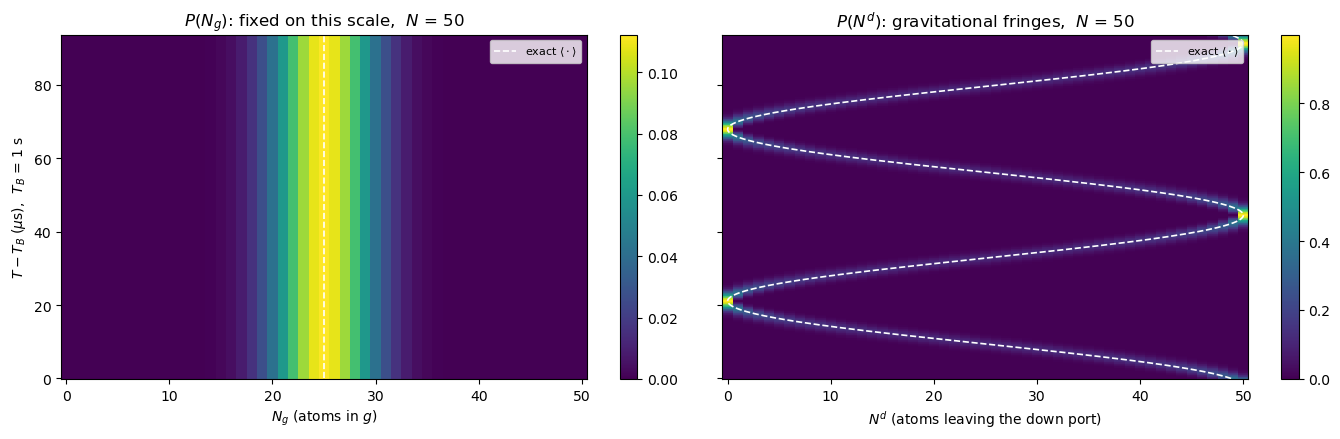

In [242]:
dOmega =  mass * g * (heights["u"] - heights["d"]) / hbar # = omegaV["u"] - omegaV["d"]  ---  gravitational frequency
times = Tbloch + np.linspace(0, 2 * 2 * np.pi / abs(dOmega), timeSteps)      # s, two gravitational fringes after T_B

# Exact single-atom probabilities at each time.
p_g_exact, p_d_exact = exact_probabilities(times)

# Simulation single-atom probabilities at each time.
results = [stats(N, T) for T in times]
P_g_map = np.array([r[0] for r in results])              # P_g_map[i, Ng] at times[i]
P_d_map = np.array([r[1] for r in results])              # P_d_map[i, Nd] at times[i]

y = (times - Tbloch) * 1e6                               # microseconds after Tbloch
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
scan_map(ax[0], times, y, P_g_map, p_g_exact, rf"$T - T_B$ ($\mu$s),  $T_B$ = {Tbloch:g} s", r"$N_g$ (atoms in $g$)")
ax[0].set_title(rf"$P(N_g)$: fixed on this scale,  $N$ = {N}")
scan_map(ax[1], times, y, P_d_map, p_d_exact, "", r"$N^d$ (atoms leaving the down port)")
ax[1].set_title(rf"$P(N^d)$: gravitational fringes,  $N$ = {N}")
plt.tight_layout(); plt.show()

**Ramsey fringe.** Two periods $2\pi/\bar\omega$ from $T = 0$. The Ramsey sequence consists of two $\pi/2$ pulses separated by a time $T$, during which the excited state of each clock accumulates the phase $\omega_I T$ relative to the ground state. At $T = 0$ the two pulses add up to a $\pi$ pulse and every atom goes from the ground ($N_g = N$) to the excited ($N_g = 0$) state. After half a period ($T = \pi / \bar\omega$) every atom is back in $g$.

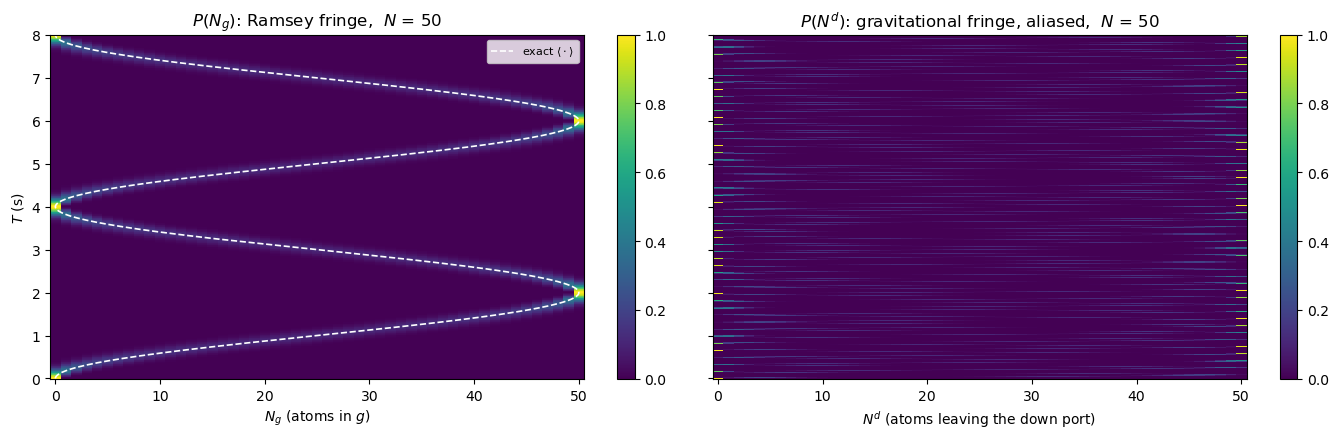

In [243]:
omega_bar = (omegaE["u"] + omegaE["d"]) / 2   # Ramsey frequency: mean clock frequency in the laser frame
times = np.linspace(0, 2 * 2 * np.pi / abs(omega_bar), timeSteps)                 # s, two Ramsey fringes

# Exact single-atom probabilities at each time.
p_g_exact, p_d_exact = exact_probabilities(times)

# Simulation single-atom probabilities at each time.
results = [stats(N, T) for T in times]
P_g_map = np.array([r[0] for r in results])              # P_g_map[i, Ng] at times[i]
P_d_map = np.array([r[1] for r in results])              # P_d_map[i, Nd] at times[i]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
scan_map(ax[0], times, times, P_g_map, p_g_exact, r"$T$ (s)", r"$N_g$ (atoms in $g$)")
ax[0].set_title(rf"$P(N_g)$: Ramsey fringe,  $N$ = {N}")
scan_map(ax[1], times, times, P_d_map, None, "", r"$N^d$ (atoms leaving the down port)")
ax[1].set_title(rf"$P(N^d)$: gravitational fringe, aliased,  $N$ = {N}")
plt.tight_layout(); plt.show()

The second map is *aliased* and $P(N^d)$ oscillates every $47\ \mu\text{s}$, much faster than the sampling step ($0.04$ s).

**Visibility.** The envelope $\mathcal V(T)$ first vanishes at $T = \pi/\Delta\omega \approx 12$ days. Both maps are aliased, and each row lands on an essentially random phase. However, the resulting pattern is not noise: at any time the mean $\langle N_g\rangle/N$, and likewise $\langle N^d\rangle/N$ with $\cos\Delta\Phi$, can only lie between $\tfrac12(1 \pm |\mathcal V|)$. The aliased points thus fill a band whose envelope is the visibility and its modulus the fringe contrast.

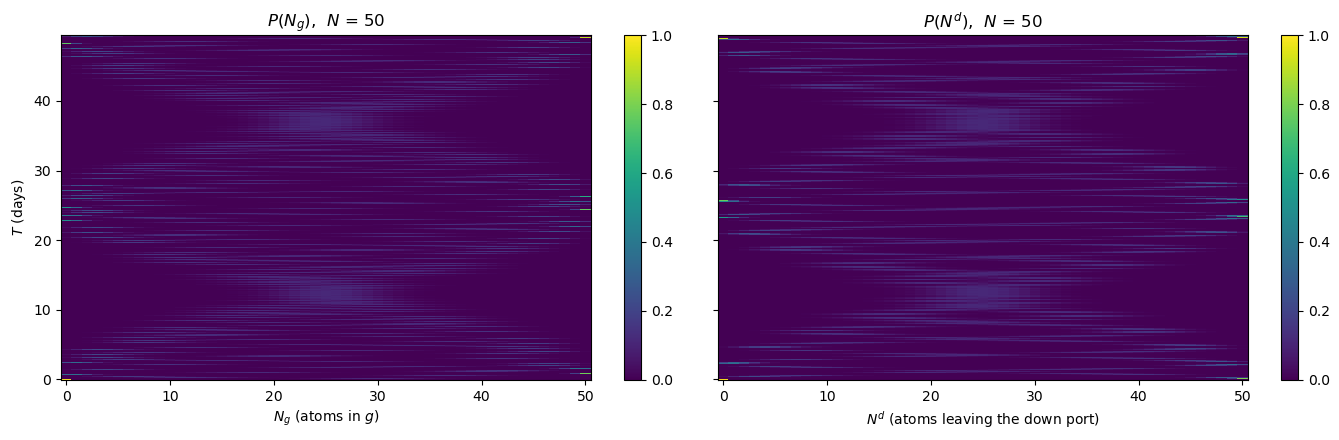

In [244]:
dw = omega0 * g * (heights["u"] - heights["d"]) / c**2 # = omegaE["u"] - omegaE["d"]  ----- redshift
times = np.linspace(0, 4 * np.pi / abs(dw), timeSteps)

# Simulation: stats returns (P(N_g), P(N^d)) at each time.
results = [stats(N, T) for T in times]
P_g_map = np.array([r[0] for r in results])              # P_g_map[i, Ng] at times[i]
P_d_map = np.array([r[1] for r in results])              # P_d_map[i, Nd] at times[i]

y = times / 86400                                         # days: the visibility has period 4 pi / domega ~ 49 days
ylabel = r"$T$ (days)"
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
scan_map(ax[0], times, y, P_g_map, None, ylabel, r"$N_g$ (atoms in $g$)")
ax[0].set_title(rf"$P(N_g)$,  $N$ = {N}")
scan_map(ax[1], times, y, P_d_map, None, "", r"$N^d$ (atoms leaving the down port)")
ax[1].set_title(rf"$P(N^d)$,  $N$ = {N}")
plt.tight_layout(); plt.show()

Ramsey and gravitational fringes probe the internal (energy) and the external (path) coherence of the atoms, respectively: each fringe exists only if the corresponding degree of freedom is in a superposition. In both, the contrast is modulated by the same envelope $\mathcal V = \cos(\Delta\omega T/2)$ as a consequence of the mass-energy equivalence: the internal energy gravitates, and the clocks at the two heights tick at different rates. Observing a modulated fringe in an experiment would thus show that mass-energy equivalence and the superposition principle coexist. Without the former, $\Delta\omega = 0$ and the envelope disappears; without the latter, the fringe itself disappears.

However, the envelope alone does not certify a superposition of the *other* degree of freedom: in $P(N_g)$ it would also appear for atoms placed at random at either height, and in $P(N^d)$ for clocks in $g$ or $e$ at random. To tell mixtures from true superpositions, each observable must be complemented by the other degree of freedom: $P(N_g)$ by resolving the output ports, $P(N^d)$ by resolving the clock state. 

Zych et al. measure $p_{\rm up} - p_{\rm down}$ without resolving the clock state, and the internal superposition is guaranteed by preparation. Paczos et al. resolve both degrees of freedom at once by $4D_g = p'^u_g - p'^d_g$, which vanishes without path coherence and loses its modulation without internal coherence.

### Zych - Nat. Commun. 2011

Following Zych et al., Nat. Commun. 2, 505 (2011), we study the visibility through the difference between the atoms leaving by the up and by the down port. For a single atom, the exact results above give

$$ p_{\rm up} - p_{\rm down} = 1 - 2p_{\rm down} = \mathcal{V}(T)\cos\Delta\Phi = \cos\Big(\frac{\Delta\omega\,T}{2}\Big)\cos\Big(\Delta\Omega\,T + \frac{\Delta\omega\,T}{2}\Big),$$

which is their Eq. (12), with $\Delta\varphi = 0$, $\Delta\omega = \Delta E\,\Delta V/\hbar c^2$, and $\Delta\Omega + \Delta\omega/2 = (mc^2 + \langle H\rangle)\,\Delta V/\hbar c^2$ for $\langle H\rangle = \Delta E/2$. Since the atoms are independent, the same quantity is measured with $N$ atoms through the mean numbers $\langle N^d\rangle = N p_{\rm down}$ and $\langle N^u\rangle = N - \langle N^d\rangle$:

$$p_{\rm up} - p_{\rm down} = \frac{\langle N^u\rangle - \langle N^d\rangle}{N}.$$

We compare the result with the same interferometer without a clock, i.e. with identical clock frequencies in the two arms ($\Delta\omega = 0$). This curve shows the effect of the gravitational field on a particle without internal structure: a fringe of frequency $\Delta\Omega$ with full visibility. The difference between the two curves, given by the loss of visibility $\mathcal V(T)$, is due to the clock experiencing different time dilation in the two arms.

Check the max |notebook - Eq. (12)| = 0.000


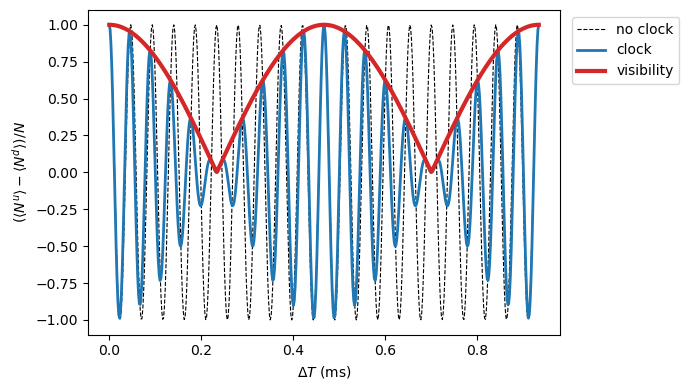

In [245]:
# Their figure has Delta Omega / Delta omega = m c^2 / (hbar omega_0) = 10 (Delta omega = 2, Delta Omega = 20 rad/s).
# The ratio does not depend on dz: we keep 87Sr and the heights of Sec. 1, and choose a fictitious clock frequency.
# Only the time axis changes: with dz = 10 um, Delta Omega = 1.3e5 rad/s instead of 20 rad/s.
omega_0_Z = mass * c**2 / (10 * hbar)                         # rad/s (~1.2e25): clock energy hbar omega_0 = m c^2 / 10

dw_Z = omega_0_Z * g * (heights["u"] - heights["d"]) / c**2   # Delta omega of the clock (~1.3e4 rad/s)
times_Z = np.linspace(0, 4 * np.pi / abs(dw_Z), timeSteps)    # s, two periods of cos(Delta omega T / 2)


def zych_curve():
    curve = []
    for t in times_Z:
        mean_g, mean_down = means(N, t)     # <N_g>/N and <N^d>/N
        mean_up = 1 - mean_down             # N^u = N - N^d
        curve.append(mean_up - mean_down)   # p_up - p_down
    return np.array(curve)


# Particle without internal structure in the gravitational field (omega_0 = 0).
omegaE, omegaV, varphi = update_parameters(omega_0=0.)
nope_clock = zych_curve()

# Particle with internal structure: the clock frequency is redshifted differently in the two arms.
omegaE, omegaV, varphi = update_parameters(omega_0=omega_0_Z)
with_clock = zych_curve()

# Eq.(12): p_up - p_down = cos(Delta omega T / 2) cos((Delta Omega + Delta omega / 2) T).
eq12 = np.cos(dw_Z * times_Z / 2) * np.cos((omegaV["u"] - omegaV["d"] + dw_Z / 2) * times_Z)
print(f"Check the max |notebook - Eq. (12)| = {np.abs(with_clock - eq12).max():.3f}")

plt.figure(figsize=(7, 4))
plt.plot(times_Z * 1e3, nope_clock, "k--", lw=0.8, label="no clock")
plt.plot(times_Z * 1e3, with_clock, color="tab:blue", lw=2, label="clock")
plt.plot(times_Z * 1e3, np.abs(np.cos(dw_Z * times_Z / 2)), color="tab:red", lw=3, label="visibility")
plt.xlabel(r"$\Delta T$ (ms)"); plt.ylabel(r"$(\langle N^u\rangle - \langle N^d\rangle)/N$")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

# Restore the parameters of Sec. 1.
omegaE, omegaV, varphi = update_parameters()

### Paczos - Quantum 2025

Paczos, Foo & Zych, Quantum (2025) consider atoms held at two heights for a time $T_B$ by Bloch oscillations, which enter only through the motional time dilation $\varepsilon_k$, while the height enters through the redshift $\varepsilon_g = g\,\Delta z/c^2$, i.e. $\Delta\omega = \omega_0\varepsilon_g$. Their model maps onto this notebook as follows:
* their excited-state phases, Eq. (4), are $\delta_I = -\omega_I T_B$, with the clock frequencies of Sec. 1;
* their external phase $e^{+i\Delta\phi}$, Eq. (8), is $\Delta\varphi = -\Delta\phi$, with $\Omega_I = 0$;
* their output $j = 0$ is our up port, and our probabilities are 4 times theirs (four trajectories are lost at their Bragg pulses).

Their $4P_g$ (Eq. 5, Fig. 3) is then our $p_g$, and their port-resolved ground population (Eq. 1) is
$$4D_g = \cos\Big(\Delta\phi + \frac{\delta_u - \delta_d}{2}\Big)\,\sin\frac{\delta_d}{2}\,\sin\frac{\delta_u}{2} = p'^u_g - p'^d_g = s_d\,s_u\cos\Delta\Phi .$$
Their Eq. (7) has a prefactor $1/8$, while Eq. (1) gives $1/4$: we follow Eq. (1), consistent with their Eq. (2).

**Plot.** $p_g$ (left) and $4D_g$ (right) against $T_B$, for a superposition of heights (orange) and for a mixture (black), obtained by averaging over 8 random path phases $\varphi_u \to \varphi_u + 2\pi k/8$. The clock readout is the same in both cases, while the port-resolved signal survives only in the superposition. The grey curve has no redshift ($\varepsilon_g = 0$).

**Parameters.** Their toy values, $\omega_{\rm L} = 40\pi$, $\omega_0 = 1.1\,\omega_{\rm L}$ and $\varepsilon_k = \varepsilon_g = 0.01$, enter only through $\omega_0 - \omega_{\rm L}$, $\omega_0\varepsilon_k$ and $\Delta\omega = \omega_0\varepsilon_g$. We obtain them with the atom and the heights of Sec. 1, a fictitious $\omega_0 \approx 10^{21}$ rad/s and $v_B \approx 2.4$ cm/s, and set `mass = 0` since their external phase is all in $\Delta\phi$.

Check the max |p_g - exact|  = 0.000
Check the max |4 D_g - exact| = 0.000
Mixture: max |p_g(mix) - p_g(sup)| = 0.000,  max |4 D_g(mix)| = 0.000


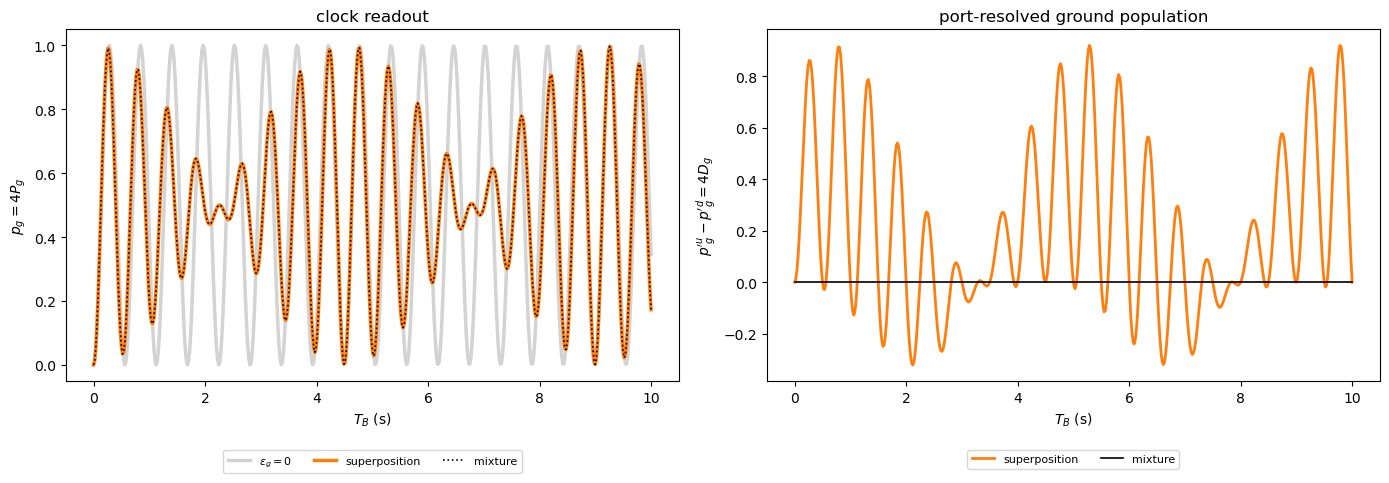

In [246]:
# Toy values of their Fig. 3, obtained with the atom and the heights of Sec. 1.
omega_L_P, eps_P = 40 * np.pi, 0.01                      # laser frequency, and eps_k = eps_g
omega_0_P = 1.1 * omega_L_P                              # their omega_0
eps_g_phys = g * (heights["u"] - heights["d"]) / c**2    # physical redshift (~1e-21)
paczos = dict(detuning=omega_0_P - omega_L_P,            # omega_0 - omega_L
              omega_0=eps_P * omega_0_P / eps_g_phys,    # fictitious clock: Delta omega = 0.44 pi rad/s
              vB=c * np.sqrt(6 * eps_g_phys),            # eps_k = vB^2 / 6c^2 = eps_g
              mass=0.0)                                  # no Omega_I: the external phase is Delta phi
Dphi_P = 0.7                                             # their Delta phi, illustrative value
N_P = min(N, 10)                                         # atoms (results per atom do not depend on N)
times_P = np.linspace(0, 10, timeSteps)                        # s, T_B


def paczos_curves(z_u, Dphi):
    # p_g = p'^u_g + p'^d_g and 4 D_g = p'^u_g - p'^d_g against T_B.
    global omegaE, omegaV, varphi                        # final_state reads the global parameters
    omegaE, omegaV, varphi = update_parameters(z_u=z_u, varphi_u=-Dphi, **paczos)
    up, down = [], []
    for t in times_P:
        sectors = final_state(N_P, t)
        # In sector Ng the row index of M is the number of ground atoms leaving by the down port.
        down_g = sum(np.arange(M.shape[0]) @ np.sum(np.abs(M)**2, axis=1) for M in sectors.values()) / N_P
        total_g = sum(Ng * np.sum(np.abs(M)**2) for Ng, M in sectors.items()) / N_P
        up.append(total_g - down_g); down.append(down_g)
    up, down = np.array(up), np.array(down)
    return up + down, up - down


p_g_grey, _ = paczos_curves(heights["d"], Dphi_P)                                    # no redshift
mix = [paczos_curves(heights["u"], Dphi_P + 2 * np.pi * k / 8) for k in range(8)]    # random path phases
p_g_mix, D_mix = np.mean(mix, axis=0)                                                # mixture
p_g_sup, D_sup = paczos_curves(heights["u"], Dphi_P)                                 # superposition (k = 0)

# Exact: p_g as in Sec. 5 (their Eq. 5) and 4 D_g = s_d s_u cos(Delta Phi) (their Eq. 1), with Delta Omega = 0.
s_d, s_u = np.sin(omegaE["d"] * times_P / 2), np.sin(omegaE["u"] * times_P / 2)
dPhi = varphi["u"] - varphi["d"] + (omegaE["u"] - omegaE["d"]) * times_P / 2
print(f"Check the max |p_g - exact|  = {np.abs(p_g_sup - exact_probabilities(times_P)[0]).max():.3f}")
print(f"Check the max |4 D_g - exact| = {np.abs(D_sup - s_d * s_u * np.cos(dPhi)).max():.3f}")
print(f"Mixture: max |p_g(mix) - p_g(sup)| = {np.abs(p_g_mix - p_g_sup).max():.3f},  max |4 D_g(mix)| = {np.abs(D_mix).max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
ax[0].plot(times_P, p_g_grey, color="lightgray", lw=2.5, label=r"$\varepsilon_g = 0$")
ax[0].plot(times_P, p_g_sup, color="tab:orange", lw=2.5, label="superposition")
ax[0].plot(times_P, p_g_mix, "k:", lw=1.2, label="mixture")
ax[0].set(xlabel=r"$T_B$ (s)", ylabel=r"$p_g = 4P_g$", title="clock readout")
ax[1].plot(times_P, D_sup, color="tab:orange", lw=2, label="superposition")
ax[1].plot(times_P, D_mix, "k", lw=1.2, label="mixture")
ax[1].set(xlabel=r"$T_B$ (s)", ylabel=r"$p'^u_g - p'^d_g = 4D_g$", title="port-resolved ground population")
for a in ax: a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

omegaE, omegaV, varphi = update_parameters()             # restore the parameters of Sec. 1

### Laser-frequency scan

At fixed $T$, scanning $\omega_{\rm L}$ gives the Ramsey fringe of $p_g$, centred at $\bar\omega = 0$, i.e. at the clock frequency of the mean height. Increasing $\Delta z$ at fixed $z_d$ shifts this resonance by $\Delta\omega/2$ and lowers its contrast to $\mathcal V$. Both effects are set by $\Delta\omega T$, which is $\sim 10^{-6}$ with the values of Sec. 1: the plot uses separations of a few metres, giving $\Delta\omega T = 0, \pi/4, \pi/2, 3\pi/4$ (the same curves hold for $\Delta z = 10\ \mu$m and $T \approx 10^6$ s). The axis is the offset $x = \omega_{\rm L} - \omega_0(1 - \varepsilon_k)$, so that no phase of order $\omega_0$ enters the computation; only `omegaE` is updated, since `omegaV` does not affect $P(N_g)$.

dz = 0.000 m:  V = 1.000,  Check the max |simulation - exact| = 0.000
dz = 2.668 m:  V = 0.924,  Check the max |simulation - exact| = 0.000
dz = 5.336 m:  V = 0.707,  Check the max |simulation - exact| = 0.000
dz = 8.004 m:  V = 0.383,  Check the max |simulation - exact| = 0.000


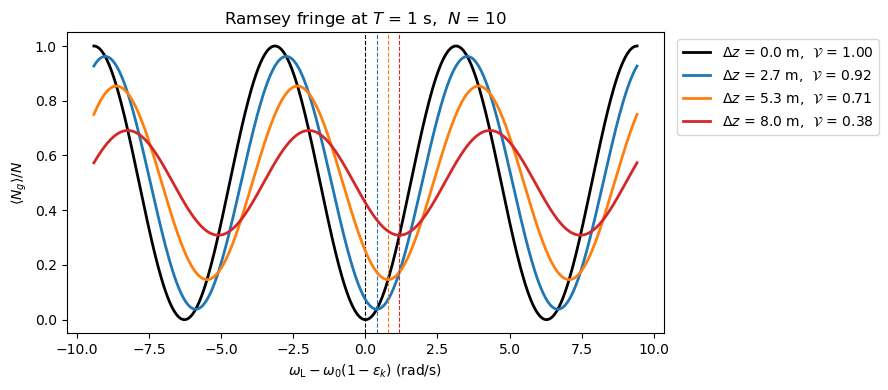

In [247]:
# Fixed time T: laser-frequency scan for Delta omega T = 0, pi/4, pi/2, 3pi/4.
T_scan, N_L, z_d = Tbloch, min(N, 10), heights["d"]
dz_full = np.pi * c**2 / (omega0 * g * T_scan)           # Delta z with Delta omega T = pi (visibility 0)
x = np.linspace(-1.5, 1.5, timeSteps) * 2 * np.pi / T_scan     # omega_L - omega0 (1 - eps_k): three Ramsey fringes

fig, ax = plt.subplots(figsize=(9, 4))
for f, colour in zip([0, 0.25, 0.5, 0.75], ["k", "tab:blue", "tab:orange", "tab:red"]):
    dz = f * dz_full
    mean_g = []
    for xL in x:
        # omega0 - omega_L = omega0 eps_k - x gives omega_I = omega0 g z_I / c^2 - x; omegaV stays as in Sec. 1.
        omegaE, _, _ = update_parameters(detuning=omega0 * eps_k - xL, z_d=z_d, z_u=z_d + dz)
        mean_g.append(means(N_L, T_scan)[0])
    V = np.cos(f * np.pi / 2)                            # visibility cos(Delta omega T / 2)
    x_res = omega0 * g * (z_d + dz / 2) / c**2           # resonance omega_bar = 0
    exact = 0.5 * (1 - V * np.cos((x_res - x) * T_scan))
    print(f"dz = {dz:.3f} m:  V = {V:.3f},  Check the max |simulation - exact| = {np.abs(np.array(mean_g) - exact).max():.3f}")
    ax.plot(x, mean_g, color=colour, lw=2, label=rf"$\Delta z$ = {dz:.1f} m,  $\mathcal{{V}}$ = {V:.2f}")
    ax.axvline(x_res, color=colour, lw=0.8, ls="--")

ax.set(xlabel=r"$\omega_{\rm L} - \omega_0(1 - \varepsilon_k)$ (rad/s)", ylabel=r"$\langle N_g\rangle/N$",
       title=rf"Ramsey fringe at $T$ = {T_scan:g} s,  $N$ = {N_L}")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

omegaE, omegaV, varphi = update_parameters()             # restore the parameters of Sec. 1